# ENME 485/691 Industrial AI, Homework 03
## Health assessment of a rotor shaft with a support vector machine (SVM)

**Objective.** Implement the analytical tools (signal processing, feature extraction and selection, SVM) and assess the health of the shaft in the rotor-bearing testbed. Compared with Homework 02 the problem is now **three-class**: healthy, unbalance level 1 (one screw) and unbalance level 2 (two screws), and the test labels are given so that a confusion matrix can be built.

**Testbed summary**

| Item | Value |
|---|---|
| Nominal rotating speed | 20 Hz (1X); measured about 21 Hz |
| Sampling rate | 2560 Hz |
| Record length | 38 400 samples = 15 s per observation |
| Training, healthy | 20 records |
| Training, unbalance level 1 | 20 records (one screw) |
| Training, unbalance level 2 | 20 records (two screws) |
| Testing | 30 records, labels given in the assignment appendix (10 per class) |

**Approaches implemented in this notebook**

1. Time-domain features suggested by the assignment (RMS, peak-to-peak, standard deviation) plus peak, crest factor, kurtosis, skewness, shape and impulse factors, computed on the raw signal.
2. Frequency-domain features: 1X, 2X, 3X harmonic amplitudes with speed tracking, low-band RMS, 1X ratio.
3. The same time-domain features computed on a 15-30 Hz band-pass filtered signal (lesson from Homework 02).
4. Three-class feature selection: filter (ANOVA F-statistic, mutual information), embedded (linear SVM weights, L1-penalized SVM) and wrapper (recursive feature elimination with cross-validation) methods, compared side by side.
5. A linear soft-margin SVM implemented **from scratch** (Pegasos sub-gradient descent on the hinge loss) and validated against scikit-learn.
6. Multi-class SVM (one-vs-one) with kernel and hyper-parameter selection by stratified cross-validation, trained on the feature subsets chosen in step 4: (A) all raw time-domain features as a baseline, (B) the ANOVA filter selection, (C) the RFECV wrapper selection, (D) the L1-SVM embedded selection.
7. Health assessment of the 30 test records: predicted class per record, confusion matrix, accuracy, precision and recall, and decision-boundary plots.

## 1. Setup
Imports, testbed constants, plotting style and a fixed color per class (blue = healthy, yellow = unbalance level 1, red = unbalance level 2, gray = test record of unknown condition).

In [1]:
# Imports, constants, and a consistent plotting style used throughout the notebook.
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import signal, stats
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.feature_selection import f_classif, mutual_info_classif, RFECV
from sklearn.svm import LinearSVC
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay

FS = 2560.0        # sampling rate [Hz]
F_ROT = 20.0       # nominal shaft speed [Hz] (1X)

DATA_DIR = next(p for p in (Path("../data/rotor-bearing-hw3"), Path("data/rotor-bearing-hw3")) if p.exists()).resolve()
OUT_DIR = Path("results"); OUT_DIR.mkdir(exist_ok=True)

CLASSES = ["healthy", "unbalance 1", "unbalance 2"]          # class index 0, 1, 2
COLORS = {"healthy": "#2a78d6", "unbalance 1": "#eda100", "unbalance 2": "#e34948"}
C_TEST = "#52514e"
CMAP = plt.matplotlib.colors.ListedColormap([COLORS[c] for c in CLASSES])
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.2, "font.size": 9.5, "legend.frameon": False,
})
pd.set_option("display.precision", 4)
print("Data folder:", DATA_DIR)

Data folder: C:\Users\yjun\code\coursework\enme691\data\rotor-bearing-hw3


## 2. Data loading
Each text file has a short header ending with an `Acceleration` marker, followed by one acceleration value per line. Training records come from three folders (`Healthy`, `Faulty/Unbalance 1`, `Faulty/Unbalance 2`). The 30 test records are the same files as in Homework 02; their true labels are taken from the assignment appendix: files whose name starts with `Data` are healthy, files recorded between 15:49 and 15:52 are unbalance level 1, and files recorded from 16:06 on are unbalance level 2.

In [2]:
# Read one record and parse the acquisition time / record index from the file name.
def load_record(path: Path) -> np.ndarray:
    lines = path.read_text().splitlines()
    start = next(i for i, l in enumerate(lines) if l.strip().lower() == "acceleration") + 1
    return np.array([float(v) for v in lines[start:] if v.strip()])

def parse_name(path: Path):
    m = re.search(r"Time (\d{4})-(\d+)", path.name)
    return m.group(1), int(m.group(2))

def load_folder(folder: Path, label):
    recs = []
    for p in sorted(folder.glob("*.txt")):
        t, idx = parse_name(p)
        recs.append({"file": p.name, "time": t, "idx": idx, "label": label, "x": load_record(p)})
    return recs

# True label of a test record, following the appendix table of the assignment.
def test_label(path: Path):
    t, _ = parse_name(path)
    if path.name.startswith("Data"):
        return 0                       # healthy
    return 1 if int(t) < 1600 else 2   # 15:49-15:52 -> level 1, 16:06-16:18 -> level 2

healthy = load_folder(DATA_DIR / "Training" / "Healthy", 0)
unbal1  = load_folder(DATA_DIR / "Training" / "Faulty" / "Unbalance 1", 1)
unbal2  = load_folder(DATA_DIR / "Training" / "Faulty" / "Unbalance 2", 2)
testing = sorted([dict(r, label=test_label(DATA_DIR / "Testing" / r["file"])) for r in load_folder(DATA_DIR / "Testing", None)],
                 key=lambda r: (r["time"], r["idx"]))
training = healthy + unbal1 + unbal2

print(f"training: {len(healthy)} healthy, {len(unbal1)} unbalance 1, {len(unbal2)} unbalance 2 | testing: {len(testing)} records")
print("test labels (from appendix):", np.bincount([r["label"] for r in testing]), "= healthy, unbalance 1, unbalance 2")
print("samples per record:", {len(r["x"]) for r in training + testing}, "->", len(healthy[0]["x"]) / FS, "s each")

training: 20 healthy, 20 unbalance 1, 20 unbalance 2 | testing: 30 records
test labels (from appendix): [10 10 10] = healthy, unbalance 1, unbalance 2
samples per record: {38400} -> 15.0 s each


## 3. Raw data description
Summary statistics of the raw acceleration per class, time waveforms and amplitude spectra. As in Homework 02 the overall vibration level is similar for all classes; the information sits at the shaft frequency (1X).

In [3]:
# Per-class summary statistics of the raw acceleration signals.
def raw_stats(recs, name):
    x = np.concatenate([r["x"] for r in recs])
    return pd.Series({"records": len(recs), "mean [g]": x.mean(), "std [g]": x.std(), "min [g]": x.min(), "max [g]": x.max()}, name=name)

pd.DataFrame([raw_stats(healthy, "healthy"), raw_stats(unbal1, "unbalance 1"), raw_stats(unbal2, "unbalance 2"), raw_stats(testing, "testing")])

,records,mean [g],std [g],min [g],max [g]
healthy,20.0,2.4306e-04,0.0806,-1.3936,0.8363
unbalance 1,20.0,7.6560e-05,0.0726,-0.5086,0.4755
unbalance 2,20.0,3.5005e-05,0.0636,-0.5204,0.5075
testing,30.0,3.2495e-04,0.0707,-0.7410,0.5033


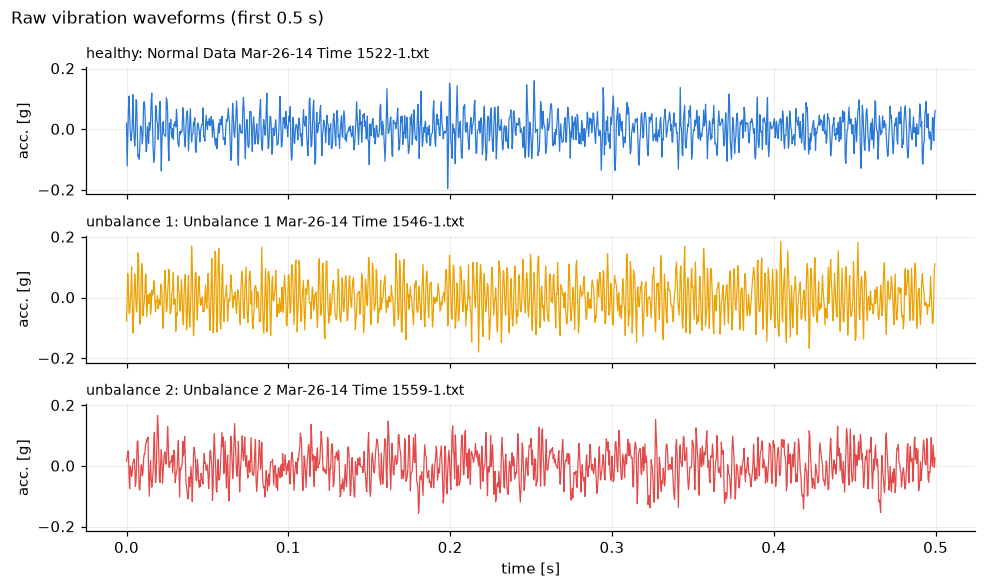

In [4]:
# Time waveforms of one record per class (first 0.5 s, about 10 shaft revolutions).
t = np.arange(len(healthy[0]["x"])) / FS
n_show = int(0.5 * FS)
fig, axes = plt.subplots(3, 1, figsize=(9, 5.4), sharex=True, sharey=True)
for ax, rec, cls in zip(axes, (healthy[0], unbal1[0], unbal2[0]), CLASSES):
    ax.plot(t[:n_show], rec["x"][:n_show], color=COLORS[cls], lw=0.8)
    ax.set_title(f"{cls}: {rec['file']}", loc="left", fontsize=9); ax.set_ylabel("acc. [g]")
axes[-1].set_xlabel("time [s]")
fig.suptitle("Raw vibration waveforms (first 0.5 s)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); plt.show()

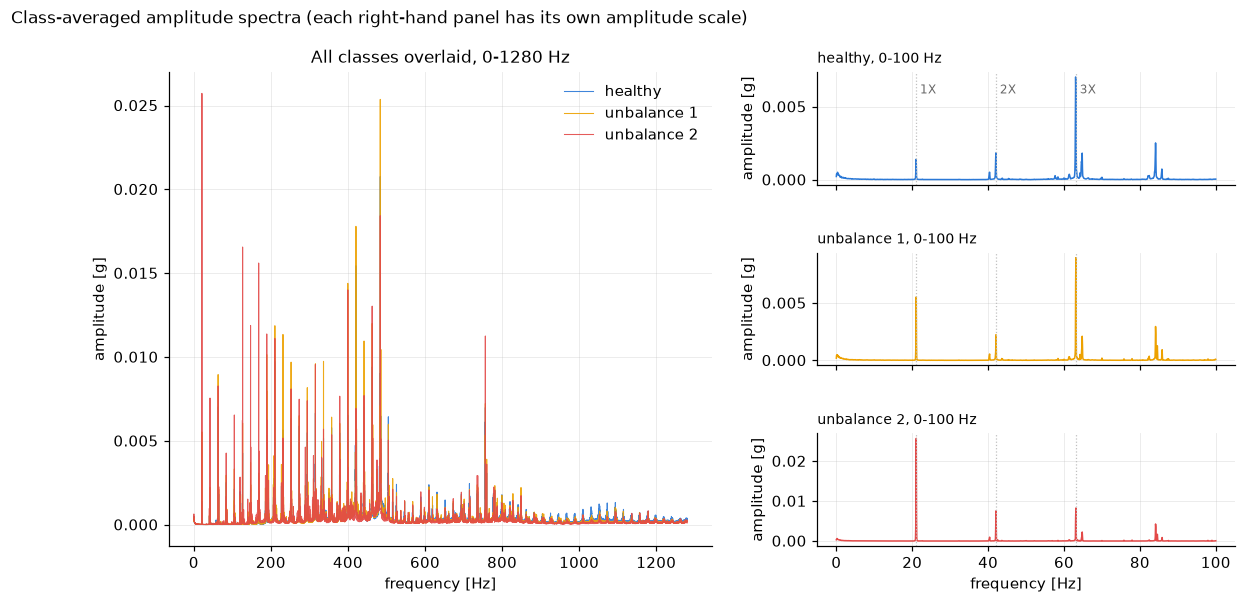

In [5]:
# Hann-windowed single-sided amplitude spectrum, and class-averaged spectra in the 0-100 Hz band.
def amplitude_spectrum(x: np.ndarray):
    x = x - x.mean(); w = np.hanning(len(x))
    return np.fft.rfftfreq(len(x), d=1 / FS), 2.0 * np.abs(np.fft.rfft(x * w)) / w.sum()

def mean_spectrum(recs):
    f = amplitude_spectrum(recs[0]["x"])[0]
    return f, np.mean([amplitude_spectrum(r["x"])[1] for r in recs], axis=0)

fig = plt.figure(figsize=(12.5, 5.6))
gs = fig.add_gridspec(3, 2, width_ratios=[1.3, 1], hspace=0.6, wspace=0.22)
ax0 = fig.add_subplot(gs[:, 0])                                  # left: all classes overlaid, full band
for recs, cls in zip((healthy, unbal1, unbal2), CLASSES):
    f, A = mean_spectrum(recs)
    ax0.plot(f, A, color=COLORS[cls], lw=0.7, label=cls, alpha=0.9)
ax0.set(title="All classes overlaid, 0-1280 Hz", xlabel="frequency [Hz]", ylabel="amplitude [g]"); ax0.legend()
for i, (recs, cls) in enumerate(zip((healthy, unbal1, unbal2), CLASSES)):   # right: one panel per class, own y-scale
    ax = fig.add_subplot(gs[i, 1]); f, A = mean_spectrum(recs); m = f <= 100
    ax.plot(f[m], A[m], color=COLORS[cls], lw=1.0)
    for k in (1, 2, 3):
        ax.axvline(k * 21.05, color="0.75", ls=":", lw=0.8)
        if i == 0: ax.text(k * 21.05 + 1, ax.get_ylim()[1] * 0.8, f"{k}X", color="0.4", fontsize=8)
    ax.set_title(f"{cls}, 0-100 Hz", loc="left", fontsize=9); ax.set_ylabel("amplitude [g]")
    if i < 2: ax.tick_params(labelbottom=False)
ax.set_xlabel("frequency [Hz]")
fig.suptitle("Class-averaged amplitude spectra (each right-hand panel has its own amplitude scale)", x=0.01, ha="left", fontsize=11)
plt.show()

## 4. Feature extraction
Three feature groups are computed for every record.

* **Raw time-domain (suggested by the assignment)**: RMS, peak-to-peak, standard deviation, peak, crest factor, kurtosis, skewness, shape factor (RMS / mean|x|) and impulse factor (peak / mean|x|).
* **Frequency-domain**: amplitudes of the 1X, 2X and 3X harmonics (1X found by a peak search in 17-23 Hz so the true 21 Hz speed is tracked), RMS of the 0-100 Hz band and the 1X / RMS ratio.
* **Band-pass time-domain**: the same nine time-domain statistics computed on the 15-30 Hz zero-phase band-pass filtered signal (1 s trimmed at each end to drop filter transients), which Homework 02 showed is what makes time-domain statistics informative.

In [6]:
# Time-domain statistics of a signal, suffixed with the signal they come from.
TD_STATS = ["rms", "p2p", "std", "peak", "crest", "kurtosis", "skewness", "shape", "impulse"]

def time_domain_features(x: np.ndarray, tag: str) -> dict:
    rms = np.sqrt(np.mean(x ** 2)); peak = np.max(np.abs(x)); mean_abs = np.mean(np.abs(x))
    return {f"rms_{tag}": rms, f"p2p_{tag}": np.ptp(x), f"std_{tag}": x.std(), f"peak_{tag}": peak,
            f"crest_{tag}": peak / rms, f"kurtosis_{tag}": stats.kurtosis(x), f"skewness_{tag}": stats.skew(x),
            f"shape_{tag}": rms / mean_abs, f"impulse_{tag}": peak / mean_abs}

# Zero-phase band-pass filter around 1X (4th-order Butterworth, forward-backward), with edge trimming.
SOS_BP = signal.butter(4, [15.0, 30.0], btype="band", fs=FS, output="sos")
TRIM = int(1.0 * FS)
def bandpass(x): return signal.sosfiltfilt(SOS_BP, x)[TRIM:-TRIM]

def band_peak(f, A, f_center, half_width):
    m = (f >= f_center - half_width) & (f <= f_center + half_width)
    i = np.argmax(A[m]); return A[m][i], f[m][i]

# Full feature vector for one record.
def extract_features(x: np.ndarray) -> dict:
    f, A = amplitude_spectrum(x)
    a1, f1 = band_peak(f, A, F_ROT, 0.15 * F_ROT)
    a2, _ = band_peak(f, A, 2 * f1, 1.0)
    a3, _ = band_peak(f, A, 3 * f1, 1.0)
    lf = (f > 0) & (f <= 100)
    d = {"A1X": a1, "A2X": a2, "A3X": a3, "f1X": f1,
         "rms_lf": np.sqrt(np.sum((A[lf] / np.sqrt(2)) ** 2)), "ratio_1X": a1 / np.sqrt(np.mean(x ** 2))}
    d |= time_domain_features(x[TRIM:-TRIM], "raw")
    d |= time_domain_features(bandpass(x), "bp")
    return d

def feature_table(recs):
    rows = []
    for r in recs:
        d = extract_features(r["x"]); d.update(file=r["file"], time=r["time"], label=r["label"]); rows.append(d)
    return pd.DataFrame(rows)

train = feature_table(training)
test = feature_table(testing)
FEAT_RAW = [f"{s}_raw" for s in TD_STATS]
FEAT_SPEC = ["A1X", "A2X", "A3X", "rms_lf", "ratio_1X"]
FEAT_BP = [f"{s}_bp" for s in TD_STATS]
FEATURES = FEAT_RAW + FEAT_SPEC + FEAT_BP
y_train, y_test = train.label.values, test.label.values
train.to_csv(OUT_DIR / "train_features.csv", index=False); test.to_csv(OUT_DIR / "test_features.csv", index=False)
print(f"{len(FEATURES)} features per record: {len(FEAT_RAW)} raw time-domain, {len(FEAT_SPEC)} frequency-domain, {len(FEAT_BP)} band-pass time-domain")
train.groupby("label")[FEATURES].mean().T.rename(columns=dict(enumerate(CLASSES)))

23 features per record: 9 raw time-domain, 5 frequency-domain, 9 band-pass time-domain


label,healthy,unbalance 1,unbalance 2
rms_raw,0.0785,0.0718,0.0629
p2p_raw,0.7711,0.6860,0.6127
std_raw,0.0785,0.0718,0.0629
peak_raw,0.4261,0.3608,0.3277
crest_raw,5.2820,5.0328,5.1459
kurtosis_raw,0.6106,0.4473,0.5773
skewness_raw,-0.1118,-0.0716,-0.0454
shape_raw,1.2753,1.2740,1.2774
impulse_raw,6.7623,6.4161,6.5910
A1X,0.0014,0.0055,0.0257


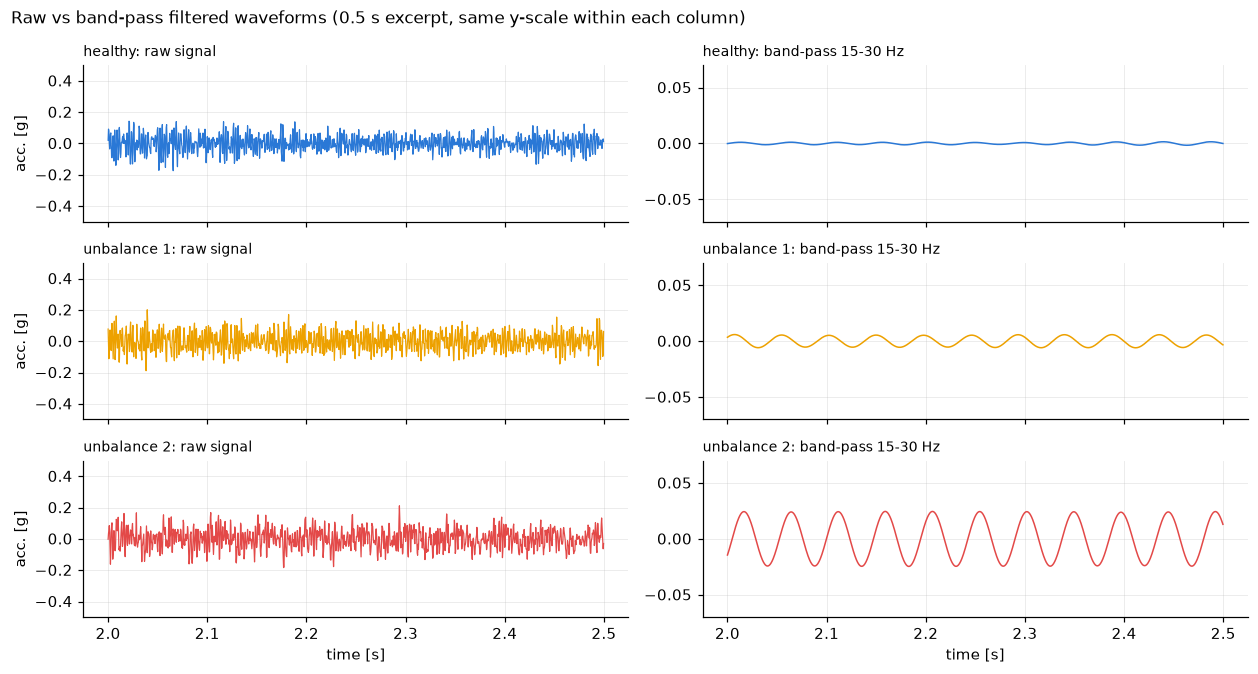

In [7]:
# Band-pass filtered time-domain data: raw (left) vs 15-30 Hz filtered (right) waveform, 0.5 s excerpt per class.
i0 = int(2.0 * FS)                                   # excerpt from t = 2.0 s to 2.5 s (clear of the trimmed filter edges)
fig, axes = plt.subplots(3, 2, figsize=(11.5, 6.2), sharex=True)
for row, (rec, cls) in enumerate(zip((healthy[0], unbal1[0], unbal2[0]), CLASSES)):
    x = rec["x"]; xb = bandpass(x)
    axes[row, 0].plot(t[i0:i0 + n_show], x[i0:i0 + n_show], color=COLORS[cls], lw=0.8); axes[row, 0].set_ylim(-0.5, 0.5)
    axes[row, 1].plot(t[i0:i0 + n_show], xb[i0 - TRIM:i0 - TRIM + n_show], color=COLORS[cls], lw=1.0); axes[row, 1].set_ylim(-0.07, 0.07)
    axes[row, 0].set_title(f"{cls}: raw signal", loc="left", fontsize=9)
    axes[row, 1].set_title(f"{cls}: band-pass 15-30 Hz", loc="left", fontsize=9)
    axes[row, 0].set_ylabel("acc. [g]")
for ax in axes[-1]:
    ax.set_xlabel("time [s]")
fig.suptitle("Raw vs band-pass filtered waveforms (0.5 s excerpt, same y-scale within each column)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); plt.show()

## 5. Feature exploration and selection
### 5.1 Filter method: ANOVA F-statistic
Box plots per class for the three feature groups, then a three-class separability ranking with the one-way ANOVA F-statistic (between-class variance divided by within-class variance; larger is better). The F-statistic generalizes the two-class Fisher ratio used in Homework 02.

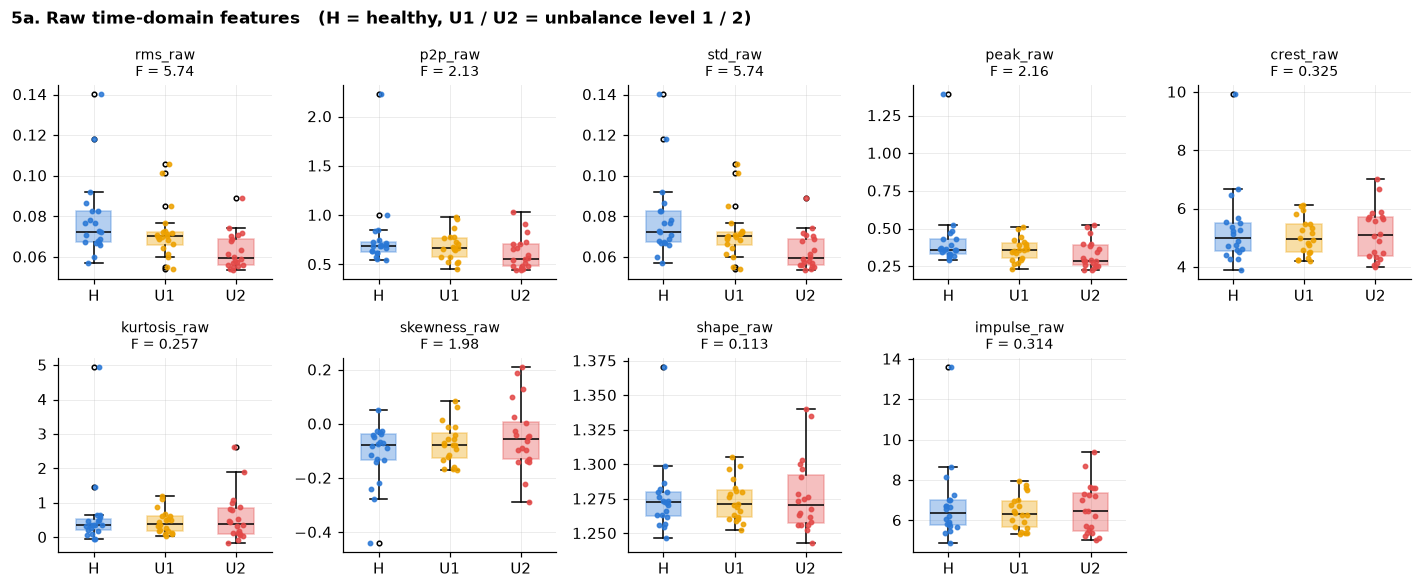

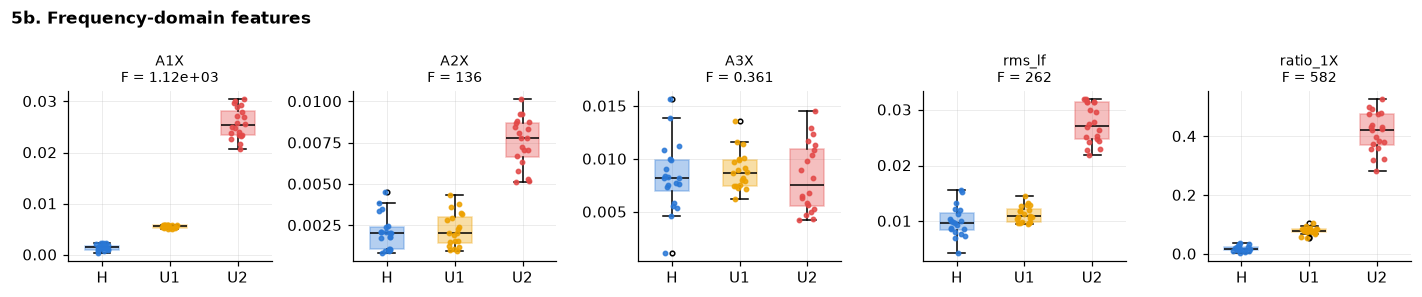

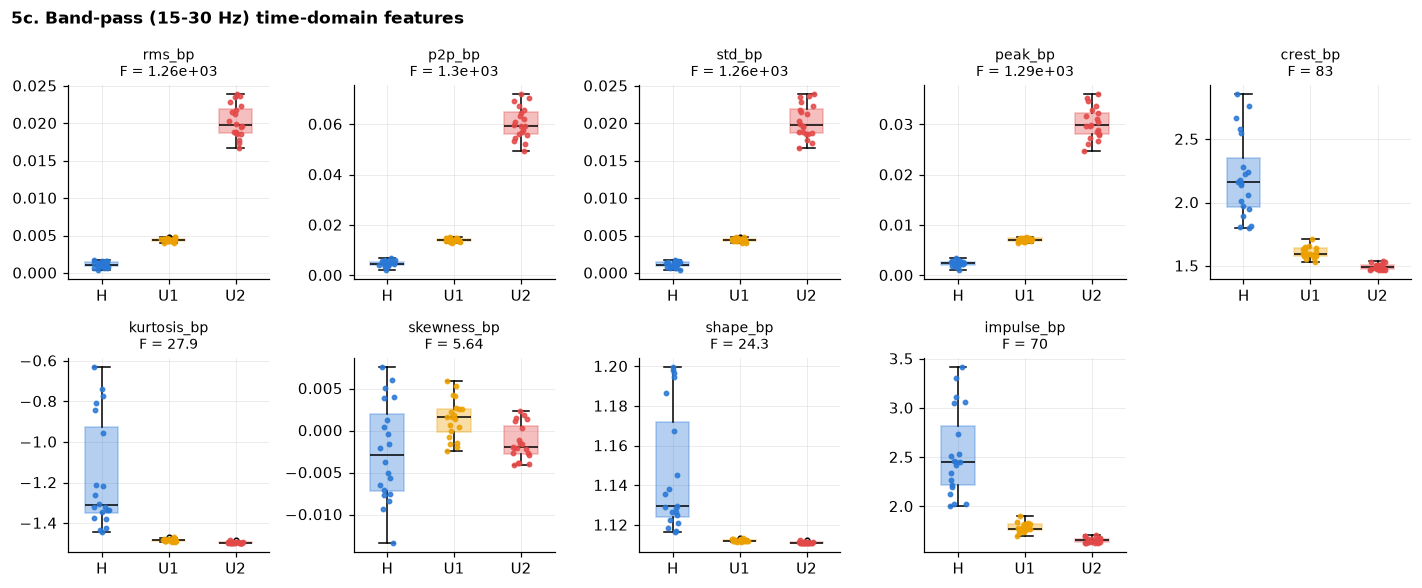

In [8]:
# Box plot helper: one panel per feature, three classes.
rng = np.random.default_rng(0)
def box_panel(ax, feat, title):
    data = [train.loc[train.label == k, feat] for k in range(3)]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops=dict(color="black", lw=1),
                    flierprops=dict(marker="o", markersize=3, markerfacecolor="none"))
    for patch, cls in zip(bp["boxes"], CLASSES):
        patch.set(facecolor=COLORS[cls], alpha=0.35, edgecolor=COLORS[cls])
    for i, (d, cls) in enumerate(zip(data, CLASSES), start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=8, color=COLORS[cls], alpha=0.85, zorder=3)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["H", "U1", "U2"]); ax.set_title(title, fontsize=9)

def box_grid(feats, suptitle, ncol=5):
    nrow = int(np.ceil(len(feats) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.7 * nrow))
    for ax, feat in zip(np.ravel(axes), feats):
        F = f_classif(train[[feat]].values, y_train)[0][0]
        box_panel(ax, feat, f"{feat}\nF = {F:.3g}")
    for ax in np.ravel(axes)[len(feats):]:
        ax.axis("off")
    fig.suptitle(suptitle, x=0.01, ha="left", fontsize=11, fontweight="bold"); fig.tight_layout(); plt.show()

box_grid(FEAT_RAW, "5a. Raw time-domain features   (H = healthy, U1 / U2 = unbalance level 1 / 2)")
box_grid(FEAT_SPEC, "5b. Frequency-domain features")
box_grid(FEAT_BP, "5c. Band-pass (15-30 Hz) time-domain features")

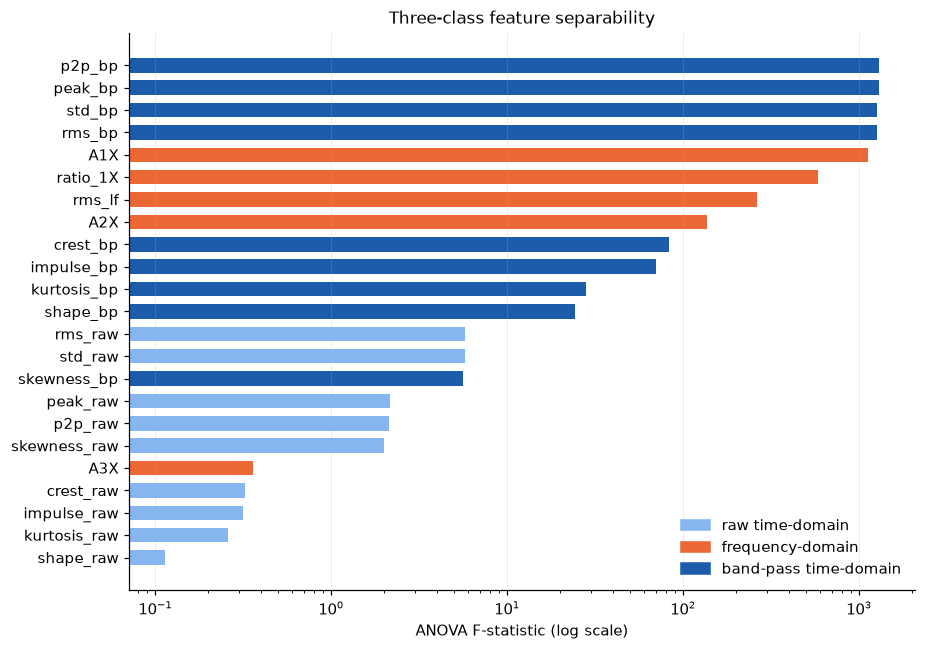

feature,F,p-value,group
p2p_bp,1.3e+03,3.11e-48,band-pass time-domain
peak_bp,1.29e+03,3.24e-48,band-pass time-domain
std_bp,1.26e+03,6.00e-48,band-pass time-domain
rms_bp,1.26e+03,6.00e-48,band-pass time-domain
A1X,1.12e+03,1.79e-46,frequency-domain
ratio_1X,582,1.20e-38,frequency-domain
rms_lf,262,1.78e-29,frequency-domain
A2X,136,2.10e-22,frequency-domain
crest_bp,83,1.30e-17,band-pass time-domain
impulse_bp,70,4.44e-16,band-pass time-domain


In [9]:
# Three-class separability ranking: ANOVA F-statistic and p-value for every feature.
F, p = f_classif(train[FEATURES].values, y_train)
ranking = pd.DataFrame({"feature": FEATURES, "F": F, "p-value": p,
                        "group": ["raw time-domain"] * len(FEAT_RAW) + ["frequency-domain"] * len(FEAT_SPEC) + ["band-pass time-domain"] * len(FEAT_BP)})
ranking = ranking.sort_values("F", ascending=False).reset_index(drop=True)

group_color = {"raw time-domain": "#86b6ef", "frequency-domain": "#eb6834", "band-pass time-domain": "#1c5cab"}
fig, ax = plt.subplots(figsize=(8.5, 6))
rk = ranking[::-1]
ax.barh(rk.feature, rk.F.clip(lower=1e-2), color=[group_color[g] for g in rk.group], height=0.65)
ax.set(xscale="log", xlabel="ANOVA F-statistic (log scale)", title="Three-class feature separability")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=c, label=g) for g, c in group_color.items()], loc="lower right")
fig.tight_layout(); plt.show()
ranking.style.format({"F": "{:.3g}", "p-value": "{:.2e}"}).hide(axis="index")

**What the ranking says.**

* **The suggested raw time-domain features do not separate the three classes.** The best of them, RMS and standard deviation, reach an F-statistic of only 5.7 (p = 0.005); peak-to-peak, peak, crest factor, kurtosis, skewness, shape and impulse factor are statistically indistinguishable between classes (p > 0.1). The raw waveform is dominated by 400-800 Hz structural content that is the same for all three conditions, so its summary statistics barely move when screws are added. Note also that RMS and standard deviation are identical features here, because the signals have zero mean.
* **Frequency-domain features separate the classes strongly.** The 1X amplitude has F = 1120: the class means are 0.0014 g, 0.0055 g and 0.0257 g with tight spreads, so the three levels form three separate clusters. The 2X harmonic (F = 136) distinguishes level 2 from the other two but not level 1 from healthy. The 3X harmonic carries no information (F = 0.36).
* **Band-pass filtering makes the time-domain statistics the strongest features of all.** On the 15-30 Hz filtered signal, peak-to-peak, peak, standard deviation and RMS reach F = 1260-1300, slightly above the 1X amplitude itself. For a sinusoid these statistics are direct estimates of its amplitude, so they measure the same 1X component that the FFT isolates, with a bit less estimation noise because the whole band around 1X contributes.
* **Shape-type features of the filtered signal** (crest, impulse, kurtosis, shape factor) separate healthy from faulty (the healthy filtered signal is noise-like, the faulty one a pure sinusoid with crest factor 1.41 and kurtosis -1.5) but do not separate the two unbalance levels, since both are sinusoids.

The four feature sets used for the SVM therefore test (A) whether the assignment's suggested raw features are sufficient, (B) the physically motivated spectral features, (C) the suggested time-domain features made informative by band-pass filtering, and (D) everything combined.

### 5.2 Wrapper and embedded methods
The ANOVA F-statistic is a **filter** method: it scores each feature alone, from the data and labels only, before any classifier is trained. It is fast and model-agnostic but univariate, so it cannot see that several features carry the same information. Two other families are therefore tried, one simple representative each, together with a second filter:

* **Filter 2, mutual information**: a non-parametric score that also captures separation by spread rather than by mean.
* **Embedded, linear SVM weights and an L1-penalized SVM**: the selection comes from the trained model itself. The magnitude of a standardized weight tells how much the feature moves the decision; an L1 penalty drives the weights of useless or redundant features to exactly zero, so the surviving set at a given penalty is the selection.
* **Wrapper, recursive feature elimination with cross-validation (RFECV)**: the linear SVM is trained, the feature with the smallest weight is removed, and the loop repeats; cross-validation accuracy at every subset size tells how few features are needed.

In [10]:
# Standardized training matrix shared by the selection methods below.
scaler_all = StandardScaler().fit(train[FEATURES].values)
Z_all = scaler_all.transform(train[FEATURES].values)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)   # stratified 5-fold splitter, reused in section 6

# Filter 2: mutual information between each feature and the class label.
mi = mutual_info_classif(Z_all, y_train, random_state=0)

# Embedded 1: weights of the tuned linear SVM on all features (one-vs-one gives three pairwise classifiers; take the mean |w|).
svm_lin = SVC(kernel="linear", C=1).fit(Z_all, y_train)
w_abs = np.abs(svm_lin.coef_).mean(axis=0)

# Embedded 2: L1-penalized linear SVM. Sweep the penalty and count the surviving (non-zero) features.
l1_path = []
for C in [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]:
    l1 = LinearSVC(penalty="l1", dual=False, C=C, max_iter=20000).fit(Z_all, y_train)
    alive = np.any(np.abs(l1.coef_) > 1e-6, axis=0)
    cv_acc = cross_val_score(make_pipeline(StandardScaler(), LinearSVC(penalty="l1", dual=False, C=C, max_iter=20000)), train[FEATURES].values, y_train, cv=CV).mean()
    l1_path.append({"C": C, "features kept": int(alive.sum()), "CV accuracy": cv_acc, "kept": [f for f, a in zip(FEATURES, alive) if a]})
l1_tab = pd.DataFrame(l1_path)
# smallest penalty that still gives perfect cross-validation accuracy
C_L1 = l1_tab.loc[l1_tab["CV accuracy"] >= l1_tab["CV accuracy"].max() - 1e-9, "C"].min()
l1_keep = l1_tab.loc[l1_tab.C == C_L1, "kept"].iloc[0]
print(f"L1-SVM: smallest C with the best CV accuracy = {C_L1} -> keeps {len(l1_keep)} feature(s): {l1_keep}")
l1_tab[["C", "features kept", "CV accuracy"]].style.format({"CV accuracy": "{:.3f}"}).hide(axis="index")

L1-SVM: smallest C with the best CV accuracy = 0.02 -> keeps 2 feature(s): ['p2p_bp', 'crest_bp']


C,features kept,CV accuracy
0.010000,1,0.333
0.020000,2,1.000
0.050000,8,0.983
0.100000,9,0.983
0.200000,9,0.983
0.500000,11,0.983
1.000000,9,0.983


RFECV: smallest subset reaching the best CV accuracy = 1 feature(s): ['peak_bp']


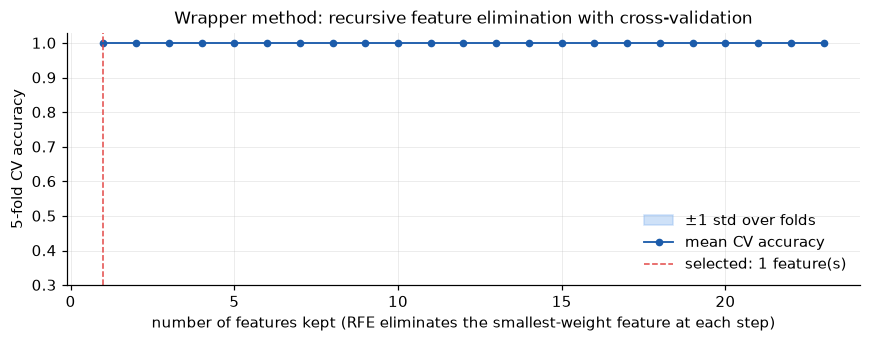

In [11]:
# Wrapper: recursive feature elimination with 5-fold cross-validation, using the linear SVM as the estimator.
rfecv = RFECV(SVC(kernel="linear", C=1), step=1, min_features_to_select=1, cv=CV, scoring="accuracy").fit(Z_all, y_train)
n_feat = np.arange(1, len(FEATURES) + 1)
mean_acc, std_acc = rfecv.cv_results_["mean_test_score"], rfecv.cv_results_["std_test_score"]
rfe_selected = [f for f, keep in zip(FEATURES, rfecv.support_) if keep]
print(f"RFECV: smallest subset reaching the best CV accuracy = {rfecv.n_features_} feature(s): {rfe_selected}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.fill_between(n_feat, mean_acc - std_acc, mean_acc + std_acc, color="#86b6ef", alpha=0.4, label="±1 std over folds")
ax.plot(n_feat, mean_acc, marker="o", ms=4, color="#1c5cab", label="mean CV accuracy")
ax.axvline(rfecv.n_features_, color=COLORS["unbalance 2"], ls="--", lw=1, label=f"selected: {rfecv.n_features_} feature(s)")
ax.set(xlabel="number of features kept (RFE eliminates the smallest-weight feature at each step)", ylabel="5-fold CV accuracy",
       ylim=(0.3, 1.03), title="Wrapper method: recursive feature elimination with cross-validation")
ax.legend(loc="lower right"); fig.tight_layout(); plt.show()

Spearman correlation between rankings (1 = identical order):
                     rank ANOVA F  rank mutual info  rank linear SVM |w|  rank RFE
rank ANOVA F                 1.00              0.95                 0.81      0.78
rank mutual info             0.95              1.00                 0.84      0.84
rank linear SVM |w|          0.81              0.84                 1.00      0.97
rank RFE                     0.78              0.84                 0.97      1.00


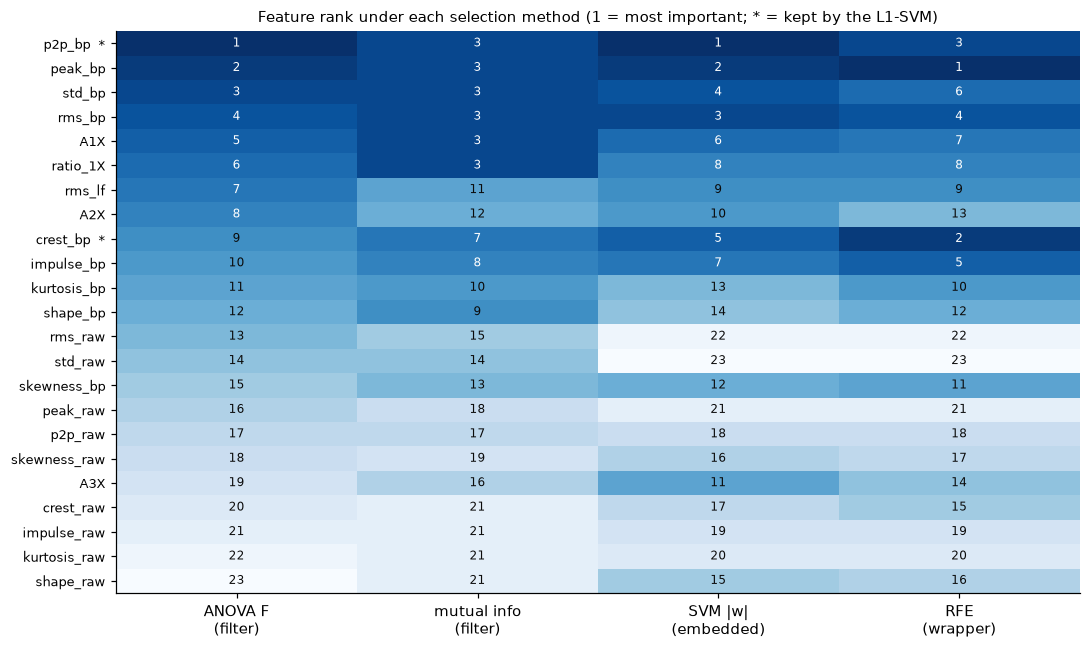

feature,rank ANOVA F,rank mutual info,rank linear SVM |w|,rank RFE,L1-SVM kept
p2p_bp,1,3,1,3,True
peak_bp,2,3,2,1,False
std_bp,3,3,4,6,False
rms_bp,4,3,3,4,False
A1X,5,3,6,7,False
ratio_1X,6,3,8,8,False
rms_lf,7,11,9,9,False
A2X,8,12,10,13,False
crest_bp,9,7,5,2,True
impulse_bp,10,8,7,5,False


In [12]:
# Side-by-side comparison of the four criteria: rank of every feature under each method (1 = most important).
comp = pd.DataFrame({"feature": FEATURES, "ANOVA F": F, "mutual info": mi, "linear SVM |w|": w_abs,
                     "RFE order": rfecv.ranking_,                      # 1 = kept to the end, larger = eliminated earlier
                     "L1-SVM kept": [f in l1_keep for f in FEATURES]})
for col in ["ANOVA F", "mutual info", "linear SVM |w|"]:
    comp[f"rank {col}"] = comp[col].rank(ascending=False).astype(int)
comp["rank RFE"] = comp["RFE order"].rank(method="min").astype(int)
comp = comp.sort_values("rank ANOVA F").reset_index(drop=True)

rank_cols = ["rank ANOVA F", "rank mutual info", "rank linear SVM |w|", "rank RFE"]
print("Spearman correlation between rankings (1 = identical order):")
print(comp[rank_cols].corr(method="spearman").round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 6))
mat = comp[rank_cols].values
im = ax.imshow(mat, cmap="Blues_r", aspect="auto", vmin=1, vmax=len(FEATURES))
ax.set_xticks(range(len(rank_cols))); ax.set_xticklabels(["ANOVA F\n(filter)", "mutual info\n(filter)", "SVM |w|\n(embedded)", "RFE\n(wrapper)"])
ax.set_yticks(range(len(comp))); ax.set_yticklabels([f + ("  *" if k else "") for f, k in zip(comp.feature, comp["L1-SVM kept"])], fontsize=8.5)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=8, color="white" if mat[i, j] <= 8 else "#0b0b0b")
ax.set_title("Feature rank under each selection method (1 = most important; * = kept by the L1-SVM)", fontsize=10); ax.grid(False)
fig.tight_layout(); plt.show()
comp[["feature"] + rank_cols + ["L1-SVM kept"]].style.hide(axis="index")

**What the three families agree on, and what each adds.**

* **Agreement.** The Spearman correlation between the four rankings is 0.78-0.97. Every method puts the band-pass amplitude statistics (peak-to-peak, peak, RMS, standard deviation of the 15-30 Hz signal) and the 1X amplitude at the top and the raw time-domain statistics in the lower half. The conclusion of section 5.1 does not depend on the selection criterion.
* **Mutual information** (second filter) gives the same picture but ties the six best features at the same rank: once a feature separates the three classes perfectly, mutual information saturates at log(3) and cannot order the features further. The ANOVA F still orders them by margin, which is more useful here.
* **Linear SVM weights** (embedded) rank crest and impulse factor of the filtered signal higher than ANOVA does (5th and 7th instead of 9th and 10th), because the classifier uses them together with an amplitude feature: amplitude separates the levels, the shape features sharpen the healthy / faulty boundary. A univariate filter cannot see this interaction.
* **L1-penalized SVM** (embedded) keeps exactly two features at the smallest penalty that still gives 100 % cross-validation accuracy: `p2p_bp` (an amplitude feature) and `crest_bp` (a shape feature). It discards the four other amplitude features as redundant copies of the same 1X information, which is the redundancy the filter ranking hides.
* **RFECV** (wrapper) shows that **one** feature, `peak_bp`, already reaches 100 % cross-validation accuracy, and that accuracy stays at 100 % for every larger subset. The data are so separable that the wrapper has nothing to trade off; its real contribution is the elimination order, which agrees with the SVM weights (correlation 0.97).

Practical reading: the problem needs one amplitude-type feature (1X amplitude or any band-pass amplitude statistic); a second, shape-type feature adds robustness at the healthy / faulty boundary; everything else is redundant or uninformative. The selected subsets are carried into section 6 as the input sets of the SVM, next to the raw time-domain features as a baseline.

## 6. Support vector machine
### 6.1 Linear SVM from scratch
A soft-margin SVM finds the hyperplane $w^\top x + b = 0$ that maximizes the margin while penalizing violations: minimize $\tfrac{\lambda}{2}\|w\|^2 + \tfrac{1}{n}\sum_i \max(0, 1 - y_i (w^\top x_i + b))$ with $y_i \in \{-1, +1\}$. The Pegasos algorithm solves this by stochastic sub-gradient descent on the hinge loss. The implementation is checked against scikit-learn's linear SVC on the two standardized features `A1X`, `A2X` for the binary task *healthy vs faulty*; the multi-class problem is then handled by scikit-learn's one-vs-one SVC.

In [13]:
# Minimal linear soft-margin SVM trained with Pegasos (stochastic sub-gradient descent on the hinge loss).
class LinearSVMScratch:
    def __init__(self, lam=0.01, n_epochs=2000, seed=0):
        self.lam, self.n_epochs, self.seed = lam, n_epochs, seed

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.where(np.asarray(y) > 0, 1.0, -1.0)
        n, d = X.shape; rng = np.random.default_rng(self.seed)
        w, b, t = np.zeros(d), 0.0, 0
        w_sum, b_sum = np.zeros(d), 0.0
        for _ in range(self.n_epochs):
            for i in rng.permutation(n):
                t += 1; eta = 1.0 / (self.lam * t)
                if y[i] * (X[i] @ w + b) < 1:                   # margin violated: hinge sub-gradient active
                    w = (1 - eta * self.lam) * w + eta * y[i] * X[i]; b += eta * y[i]
                else:
                    w = (1 - eta * self.lam) * w
                w_sum += w; b_sum += b
        self.coef_, self.intercept_ = w_sum / t, b_sum / t     # averaged iterate (more stable)
        self.hinge_ = np.mean(np.maximum(0, 1 - y * (X @ self.coef_ + self.intercept_)))
        return self

    def decision_function(self, X): return np.asarray(X, float) @ self.coef_ + self.intercept_
    def predict(self, X): return (self.decision_function(X) >= 0).astype(int)

# Binary check (healthy = 0 vs faulty = 1) on two standardized features.
Xb = train[["A1X", "A2X"]].values; yb = (y_train > 0).astype(int)
scaler_b = StandardScaler().fit(Xb); Zb = scaler_b.transform(Xb)
lam = 0.01; C_equiv = 1.0 / (lam * len(Zb))                      # Pegasos lambda <-> sklearn C = 1 / (lambda n)
scratch = LinearSVMScratch(lam=lam).fit(Zb, yb)
sk = SVC(kernel="linear", C=C_equiv).fit(Zb, yb)
print(f"scratch : w = {scratch.coef_.round(3)}, b = {scratch.intercept_:.3f}, mean hinge loss = {scratch.hinge_:.4f}")
print(f"sklearn : w = {sk.coef_[0].round(3)}, b = {sk.intercept_[0]:.3f}  (C = {C_equiv:.3g})")
print("training accuracy scratch / sklearn:", accuracy_score(yb, scratch.predict(Zb)), "/", accuracy_score(yb, sk.predict(Zb)))
print("direction cosine between the two weight vectors:", np.dot(scratch.coef_, sk.coef_[0]) / np.linalg.norm(scratch.coef_) / np.linalg.norm(sk.coef_[0]))

scratch : w = [ 5.22  -0.035], b = 3.557, mean hinge loss = 0.0599
sklearn : w = [ 5.218 -0.1  ], b = 3.508  (C = 1.67)
training accuracy scratch / sklearn: 1.0 / 1.0
direction cosine between the two weight vectors: 0.9999208836378652


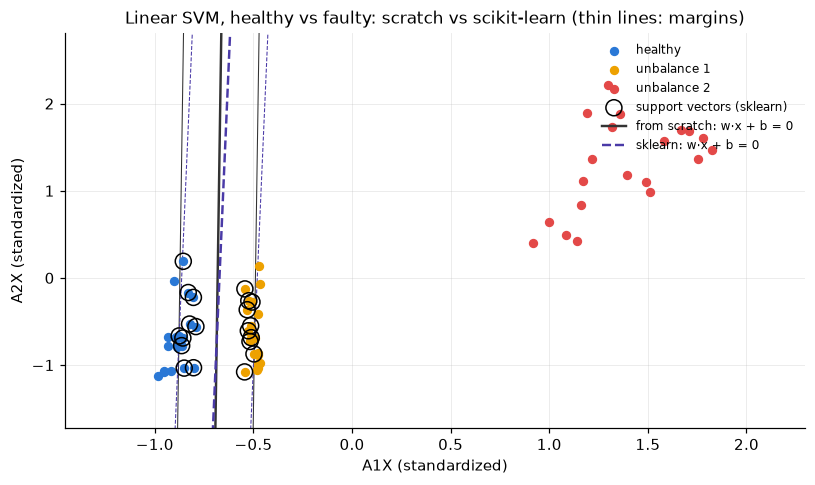

In [14]:
# Visual check: both hyperplanes (and sklearn's margin / support vectors) on the standardized A1X-A2X plane.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for k, cls in enumerate(CLASSES):
    m = y_train == k
    ax.scatter(Zb[m, 0], Zb[m, 1], s=26, color=COLORS[cls], label=cls, zorder=3)
ax.scatter(Zb[sk.support_, 0], Zb[sk.support_, 1], s=110, facecolor="none", edgecolor="black", lw=1.0, label="support vectors (sklearn)", zorder=4)
xx = np.linspace(Zb[:, 0].min() - 0.3, Zb[:, 0].max() + 0.3, 200)
for mdl, c, name, ls in [(scratch, "0.2", "from scratch", "-"), (sk, "#4a3aa7", "sklearn", "--")]:
    w, b = (mdl.coef_, mdl.intercept_) if mdl is scratch else (mdl.coef_[0], mdl.intercept_[0])
    for off, lw in [(0, 1.6), (1, 0.7), (-1, 0.7)]:
        ax.plot(xx, (off - b - w[0] * xx) / w[1], color=c, ls=ls, lw=lw, label=f"{name}: w·x + b = 0" if off == 0 else None)
ax.set(xlabel="A1X (standardized)", ylabel="A2X (standardized)", ylim=(Zb[:, 1].min() - 0.6, Zb[:, 1].max() + 0.6),
       title="Linear SVM, healthy vs faulty: scratch vs scikit-learn (thin lines: margins)")
ax.legend(loc="upper right", fontsize=8); fig.tight_layout(); plt.show()

### 6.2 Multi-class SVM: kernel and hyper-parameter selection
The SVM is trained on the feature subsets chosen by the selection methods of section 5, so that selection feeds prediction. Set A keeps all nine raw time-domain features as a baseline that shows what happens without selection. Set B is the ANOVA filter selection (features with F above 100). Set C is the wrapper selection of RFECV. Set D is the embedded selection of the L1-penalized SVM. For each set a pipeline (standardization + SVC) is tuned by grid search over the kernel (linear, RBF, polynomial), the penalty C and the RBF width gamma, using stratified 5-fold cross-validation on the 60 training records. Because the informative sets separate the classes perfectly, many grid points tie at 100 % cross-validation accuracy. Ties are broken with a training-only rule, the simplest kernel first (linear before RBF before polynomial) and then the largest C, which for separable data is the hard-margin solution that places the boundary midway between the closest training records of neighbouring classes. The three classes are handled with one-vs-one voting.

In [15]:
# Feature sets and the hyper-parameter grid.
FEATURE_SETS = {
    "A: raw baseline":     FEAT_RAW,                                           # no selection, all raw time-domain features
    "B: ANOVA filter":     [f for f, Fv in zip(FEATURES, F) if Fv > 100],      # filter method, section 5.1
    "C: RFECV wrapper":    rfe_selected,                                       # wrapper method, section 5.2
    "D: L1-SVM embedded":  l1_keep,                                            # embedded method, section 5.2
}
for name, feats in FEATURE_SETS.items():
    print(f"{name:20s} {len(feats):2d} feature(s): {feats}")
GRID = [
    {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10, 100]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]},
    {"svc__kernel": ["poly"], "svc__C": [0.1, 1, 10], "svc__degree": [2, 3], "svc__gamma": ["scale"]},
]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Tie-break among grid points with the best mean CV accuracy: simplest kernel first, then the largest C (max margin).
def pick_best(cv_results):
    df = pd.DataFrame(cv_results)
    cand = df[df.mean_test_score >= df.mean_test_score.max() - 1e-12].copy()
    cand["kernel_rank"] = cand["param_svc__kernel"].map({"linear": 0, "rbf": 1, "poly": 2})
    cand["C"] = cand["param_svc__C"].astype(float)
    return int(cand.sort_values(["kernel_rank", "C"], ascending=[True, False]).index[0])

searches, rows = {}, []
for name, feats in FEATURE_SETS.items():
    pipe = make_pipeline(StandardScaler(), SVC())
    gs = GridSearchCV(pipe, GRID, cv=CV, scoring="accuracy", refit=pick_best).fit(train[feats].values, y_train)
    gs.best_params_ = gs.cv_results_["params"][gs.best_index_]            # not filled automatically when refit is a callable
    gs.best_score_ = gs.cv_results_["mean_test_score"][gs.best_index_]
    searches[name] = gs
    best = gs.best_params_
    rows.append({"feature set": name, "n features": len(feats), "best kernel": best["svc__kernel"], "C": best["svc__C"],
                 "gamma / degree": best.get("svc__gamma", best.get("svc__degree", "-")),
                 "CV accuracy": gs.best_score_, "CV std": gs.cv_results_["std_test_score"][gs.best_index_],
                 "train accuracy": gs.best_estimator_.score(train[feats].values, y_train)})
cv_table = pd.DataFrame(rows).set_index("feature set")
cv_table.style.format({"CV accuracy": "{:.3f}", "CV std": "{:.3f}", "train accuracy": "{:.3f}"})

A: raw baseline       9 feature(s): ['rms_raw', 'p2p_raw', 'std_raw', 'peak_raw', 'crest_raw', 'kurtosis_raw', 'skewness_raw', 'shape_raw', 'impulse_raw']
B: ANOVA filter       8 feature(s): ['A1X', 'A2X', 'rms_lf', 'ratio_1X', 'rms_bp', 'p2p_bp', 'std_bp', 'peak_bp']
C: RFECV wrapper      1 feature(s): ['peak_bp']
D: L1-SVM embedded    2 feature(s): ['p2p_bp', 'crest_bp']


,n features,best kernel,C,gamma / degree,CV accuracy,CV std,train accuracy
feature set,,,,,,,
A: raw baseline,9,linear,1,-,0.483,0.122,0.617
B: ANOVA filter,8,linear,100,-,1.000,0.000,1.000
C: RFECV wrapper,1,linear,100,-,1.000,0.000,1.000
D: L1-SVM embedded,2,linear,100,-,1.000,0.000,1.000


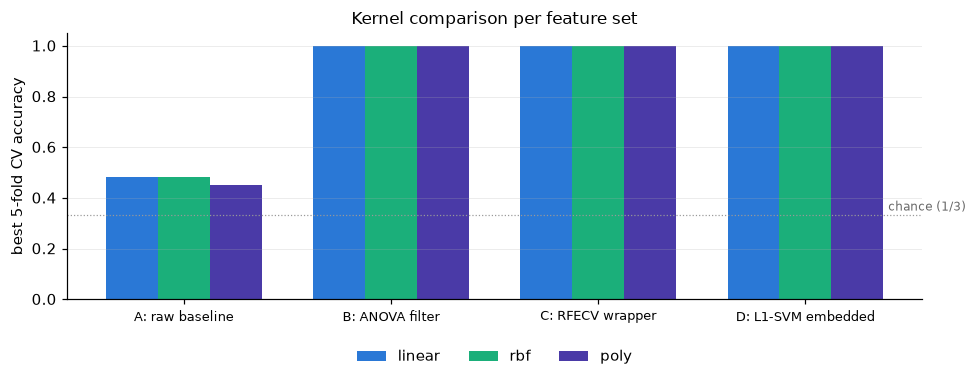

In [16]:
# How the kernels compare within each feature set (best C / gamma per kernel).
fig, ax = plt.subplots(figsize=(9, 3.6))
width = 0.25; kernels = ["linear", "rbf", "poly"]; kcol = {"linear": "#2a78d6", "rbf": "#1baf7a", "poly": "#4a3aa7"}
for j, k in enumerate(kernels):
    vals = []
    for name, gs in searches.items():
        res = pd.DataFrame(gs.cv_results_); vals.append(res.loc[res["param_svc__kernel"] == k, "mean_test_score"].max())
    ax.bar(np.arange(len(searches)) + (j - 1) * width, vals, width, color=kcol[k], label=k)
ax.set_xticks(np.arange(len(searches))); ax.set_xticklabels([n.split(":")[0] + ":" + n.split(":")[1][:22] for n in searches], fontsize=8.5)
ax.axhline(1 / 3, color="0.6", ls=":", lw=0.8); ax.text(len(searches) - 0.6, 0.35, "chance (1/3)", color="0.4", fontsize=8)
ax.set(ylim=(0, 1.05), ylabel="best 5-fold CV accuracy", title="Kernel comparison per feature set")
ax.grid(axis="x", visible=False); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3); fig.tight_layout(); plt.show()

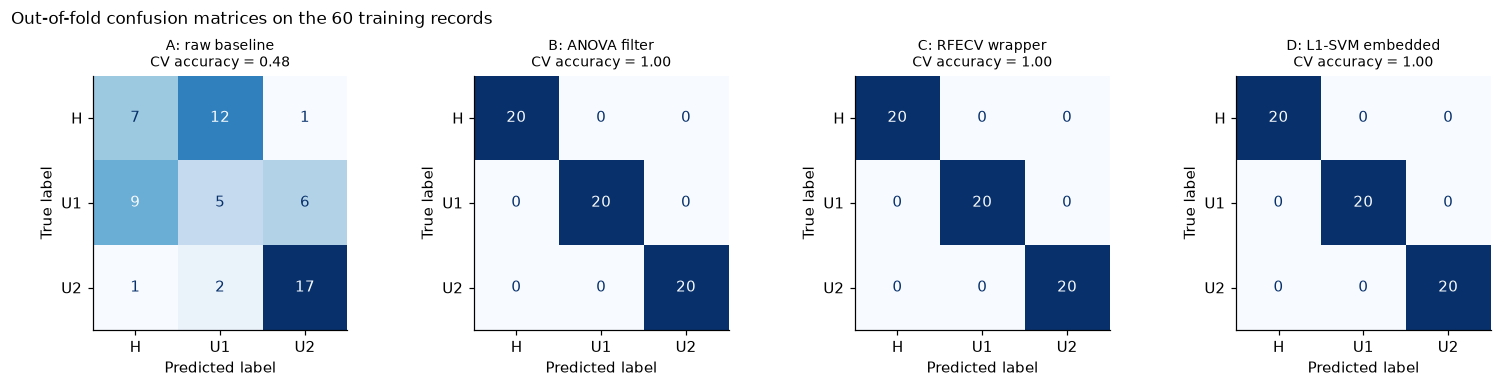

In [17]:
# Cross-validated confusion matrices on the training data (out-of-fold predictions of the tuned models).
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (name, gs) in zip(axes, searches.items()):
    feats = FEATURE_SETS[name]
    y_oof = cross_val_predict(gs.best_estimator_, train[feats].values, y_train, cv=CV)
    ConfusionMatrixDisplay(confusion_matrix(y_train, y_oof), display_labels=["H", "U1", "U2"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nCV accuracy = {accuracy_score(y_train, y_oof):.2f}", fontsize=9); ax.grid(False)
fig.suptitle("Out-of-fold confusion matrices on the 60 training records", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); plt.show()

### 6.3 Decision regions of the tuned SVM
The two smallest selected sets are visualized directly. Set C has a single feature, so its SVM reduces to two thresholds on that feature, drawn as vertical lines over the training and test records. Set D has two features, so its decision regions, support vectors and the 30 test records are drawn in that plane.

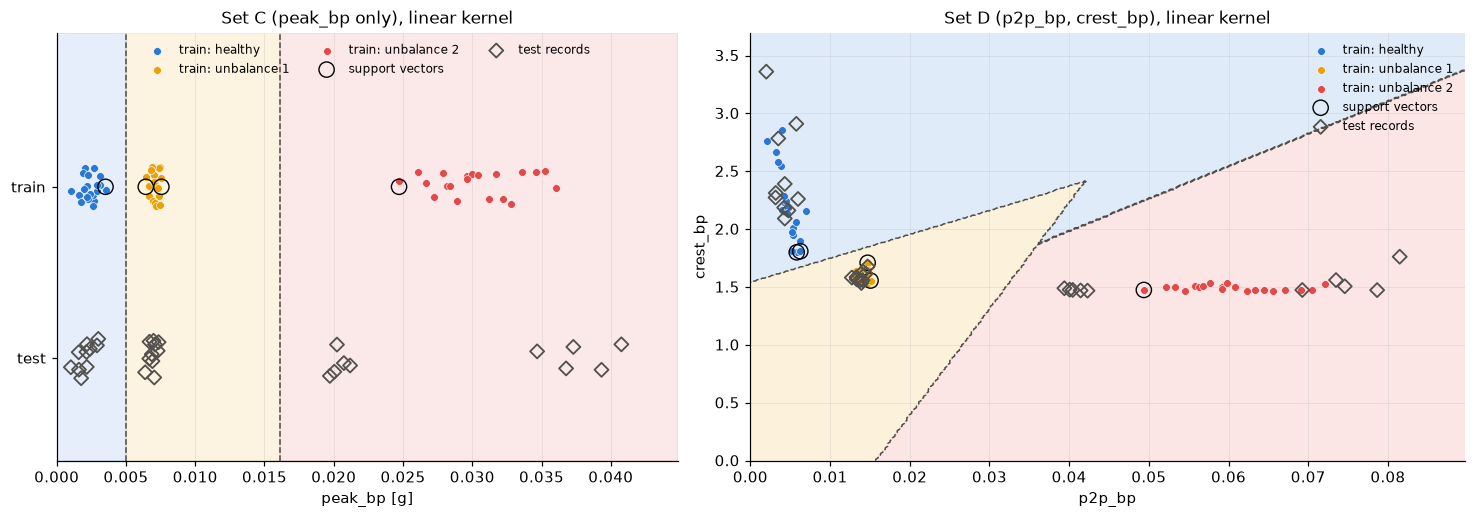

In [18]:
# Decision plots of the selected sets. Left: one-feature SVM (set C). Right: two-feature SVM (set D) with support vectors and test records.
def plot_regions(ax, feats, params, title):
    pipe = make_pipeline(StandardScaler(), SVC(**{k.replace("svc__", ""): v for k, v in params.items()}))
    pipe.fit(train[feats].values, y_train)
    x0 = np.concatenate([train[feats[0]], test[feats[0]]]); x1 = np.concatenate([train[feats[1]], test[feats[1]]])
    g0 = np.linspace(0, x0.max() * 1.1, 300); g1 = np.linspace(0, x1.max() * 1.1, 300)
    G0, G1 = np.meshgrid(g0, g1)
    Z = pipe.predict(np.c_[G0.ravel(), G1.ravel()]).reshape(G0.shape)
    ax.contourf(G0, G1, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=[COLORS[c] for c in CLASSES], alpha=0.14)
    ax.contour(G0, G1, Z, levels=[0.5, 1.5], colors="0.3", linewidths=1.0, linestyles="--")
    for k, cls in enumerate(CLASSES):
        m = y_train == k
        ax.scatter(train.loc[m, feats[0]], train.loc[m, feats[1]], s=26, color=COLORS[cls], edgecolor="white", lw=0.4, label=f"train: {cls}", zorder=3)
    sv = pipe[-1].support_
    ax.scatter(train.iloc[sv][feats[0]], train.iloc[sv][feats[1]], s=100, facecolor="none", edgecolor="black", lw=0.9, label="support vectors", zorder=4)
    ax.scatter(test[feats[0]], test[feats[1]], s=42, marker="D", facecolor="none", edgecolor=C_TEST, lw=1.2, label="test records", zorder=5)
    ax.set(xlabel=feats[0], ylabel=feats[1], title=title, xlim=(g0[0], g0[-1]), ylim=(g1[0], g1[-1]))
    return pipe

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})
rng = np.random.default_rng(1)
# --- set C: one feature -> thresholds on the feature axis
nameC = "C: RFECV wrapper"; fC = FEATURE_SETS[nameC]; pipeC = searches[nameC].best_estimator_
ax = axes[0]
if len(fC) == 1:
    xg = np.linspace(0, max(train[fC[0]].max(), test[fC[0]].max()) * 1.1, 4000)
    zc = pipeC.predict(xg[:, None])
    for k, cls in enumerate(CLASSES):
        if (zc == k).any(): ax.axvspan(xg[zc == k].min(), xg[zc == k].max(), color=COLORS[cls], alpha=0.12)
    for b in xg[1:][np.diff(zc) != 0]:
        ax.axvline(b, color="0.3", ls="--", lw=1.0)
    for k, cls in enumerate(CLASSES):
        v = train.loc[train.label == k, fC[0]]
        ax.scatter(v, np.full(len(v), 1) + rng.uniform(-0.12, 0.12, len(v)), s=26, color=COLORS[cls], edgecolor="white", lw=0.4, label=f"train: {cls}", zorder=3)
    sv = pipeC[-1].support_
    ax.scatter(train.iloc[sv][fC[0]], np.full(len(sv), 1), s=100, facecolor="none", edgecolor="black", lw=0.9, label="support vectors", zorder=4)
    ax.scatter(test[fC[0]], np.zeros(len(test)) + rng.uniform(-0.12, 0.12, len(test)), s=42, marker="D", facecolor="none", edgecolor=C_TEST, lw=1.2, label="test records", zorder=5)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["test", "train"]); ax.set_ylim(-0.6, 1.9); ax.grid(axis="y", visible=False)
    ax.set(xlabel=f"{fC[0]} [g]", xlim=(xg[0], xg[-1]), title=f"Set C ({fC[0]} only), {searches[nameC].best_params_['svc__kernel']} kernel")
    ax.legend(loc="upper center", ncol=3, fontsize=8)
else:
    plot_regions(ax, fC[:2], searches[nameC].best_params_, f"Set C ({fC[0]}, {fC[1]})"); ax.legend(loc="upper right", fontsize=8)
# --- set D: two features -> decision regions
nameD = "D: L1-SVM embedded"; fD = FEATURE_SETS[nameD]
plot_regions(axes[1], fD[:2], searches[nameD].best_params_, f"Set D ({fD[0]}, {fD[1]}), {searches[nameD].best_params_['svc__kernel']} kernel")
axes[1].legend(loc="upper right", fontsize=8); fig.tight_layout(); plt.show()

## 7. Health assessment of the test data
Each tuned SVM predicts the class of the 30 test records. The true class of every test record is listed in the appendix of the homework document and is used only to score the predictions with a confusion matrix, accuracy, and per-class precision and recall. The primary model is the selected set with the best cross-validation accuracy, ties broken by the smaller number of features.

In [19]:
# Predict the test records with every tuned model and score against the appendix labels.
res = test[["file", "time"] + FEATURES].copy()
res.insert(0, "#", np.arange(1, len(res) + 1))
res["true"] = [CLASSES[k] for k in y_test]
acc_rows = []
for name, gs in searches.items():
    key = name.split(":")[0]
    pred = gs.best_estimator_.predict(test[FEATURE_SETS[name]].values)
    res[f"pred_{key}"] = [CLASSES[k] for k in pred]
    acc_rows.append({"feature set": name, "CV accuracy": gs.best_score_, "test accuracy": accuracy_score(y_test, pred),
                     "test errors": int((pred != y_test).sum())})
acc_table = pd.DataFrame(acc_rows).set_index("feature set")

# Primary model: best CV accuracy, fewer features on ties.
order = sorted(searches, key=lambda n: (-searches[n].best_score_, len(FEATURE_SETS[n])))
BEST = order[0]; best_key = BEST.split(":")[0]
res["predicted"] = res[f"pred_{best_key}"]; res["correct"] = res.predicted == res.true
res.to_csv(OUT_DIR / "test_health_assessment.csv", index=False)
print("primary model:", BEST, "|", searches[BEST].best_params_)
acc_table.style.format({"CV accuracy": "{:.3f}", "test accuracy": "{:.3f}"})

primary model: C: RFECV wrapper | {'svc__C': 100, 'svc__kernel': 'linear'}


,CV accuracy,test accuracy,test errors
feature set,,,
A: raw baseline,0.483,0.333,20
B: ANOVA filter,1.000,1.000,0
C: RFECV wrapper,1.000,1.000,0
D: L1-SVM embedded,1.000,1.000,0


In [20]:
# Sensitivity check for the one-feature set C: where does the level-1 / level-2 threshold land for different C values that all tie at 100 % CV accuracy?
fC = FEATURE_SETS["C: RFECV wrapper"]
xg = np.linspace(0, max(train[fC[0]].max(), test[fC[0]].max()) * 1.1, 20000)
rows_c = []
for C in [0.01, 0.1, 1, 10, 100]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C)).fit(train[fC].values, y_train)
    z = pipe.predict(xg[:, None]); thr = xg[1:][np.diff(z) != 0]
    cv_acc = cross_val_score(make_pipeline(StandardScaler(), SVC(kernel="linear", C=C)), train[fC].values, y_train, cv=CV).mean()
    pred = pipe.predict(test[fC].values)
    rows_c.append({"C": C, "CV accuracy": cv_acc, "threshold H/U1 [g]": thr[0], "threshold U1/U2 [g]": thr[1],
                   "test accuracy": accuracy_score(y_test, pred), "records 26-30 labelled": CLASSES[int(np.bincount(pred[25:30]).argmax())]})
gap = (train.loc[train.label == 1, fC[0]].max(), train.loc[train.label == 2, fC[0]].min())
print(f"{fC[0]}: training gap between unbalance 1 and unbalance 2 = {gap[0]:.4f} to {gap[1]:.4f} g (midpoint {np.mean(gap):.4f} g); "
      f"test records 26-30 lie at {test[fC[0]].iloc[25:30].min():.4f}-{test[fC[0]].iloc[25:30].max():.4f} g")
pd.DataFrame(rows_c).style.format({"CV accuracy": "{:.3f}", "threshold H/U1 [g]": "{:.4f}", "threshold U1/U2 [g]": "{:.4f}", "test accuracy": "{:.3f}"}).hide(axis="index")

peak_bp: training gap between unbalance 1 and unbalance 2 = 0.0076 to 0.0247 g (midpoint 0.0161 g); test records 26-30 lie at 0.0197-0.0212 g


C,CV accuracy,threshold H/U1 [g],threshold U1/U2 [g],test accuracy,records 26-30 labelled
0.010000,1.000,0.0043,0.0213,0.833,unbalance 1
0.100000,1.000,0.0043,0.0180,1.000,unbalance 2
1.000000,1.000,0.0047,0.0164,1.000,unbalance 2
10.000000,1.000,0.0049,0.0161,1.000,unbalance 2
100.000000,1.000,0.0050,0.0161,1.000,unbalance 2


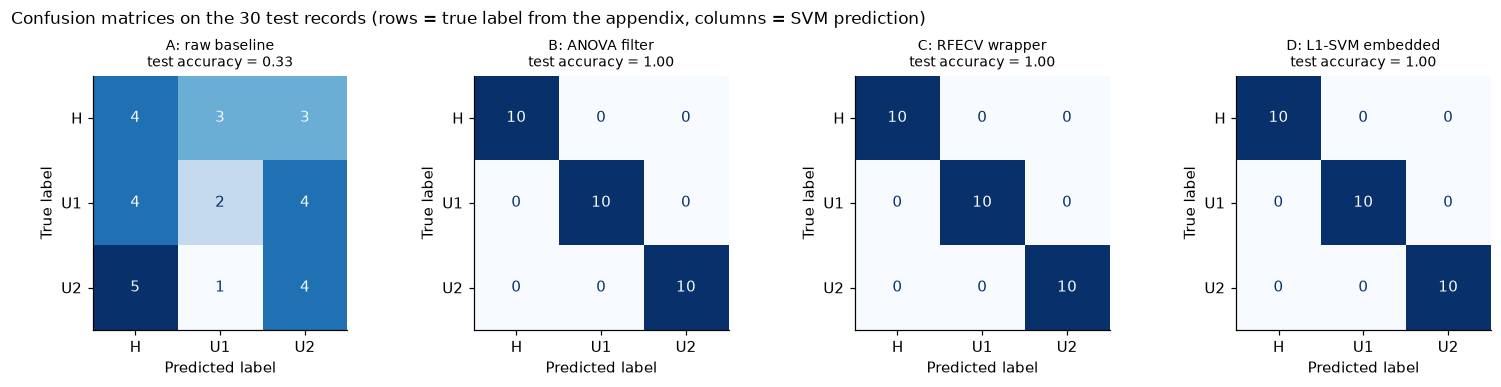

In [21]:
# Confusion matrices on the 30 test records for all four feature sets.
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, name in zip(axes, searches):
    key = name.split(":")[0]
    cm = confusion_matrix(res.true.map(CLASSES.index), res[f"pred_{key}"].map(CLASSES.index), labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=["H", "U1", "U2"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\ntest accuracy = {acc_table.loc[name, 'test accuracy']:.2f}", fontsize=9); ax.grid(False)
fig.suptitle("Confusion matrices on the 30 test records (rows = true label from the appendix, columns = SVM prediction)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); plt.show()

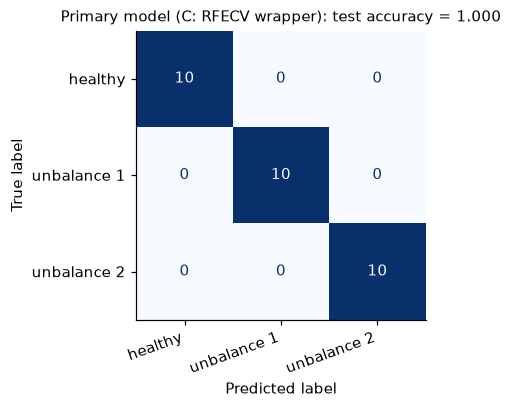

              precision    recall  f1-score   support

     healthy      1.000     1.000     1.000        10
 unbalance 1      1.000     1.000     1.000        10
 unbalance 2      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



In [22]:
# Primary model: confusion matrix and per-class precision / recall.
y_pred_best = res.predicted.map(CLASSES.index).values
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_best, labels=[0, 1, 2]), display_labels=CLASSES).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Primary model ({BEST}): test accuracy = {accuracy_score(y_test, y_pred_best):.3f}", fontsize=9.5); ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right"); fig.tight_layout(); plt.show()
print(classification_report(y_test, y_pred_best, target_names=CLASSES, digits=3))

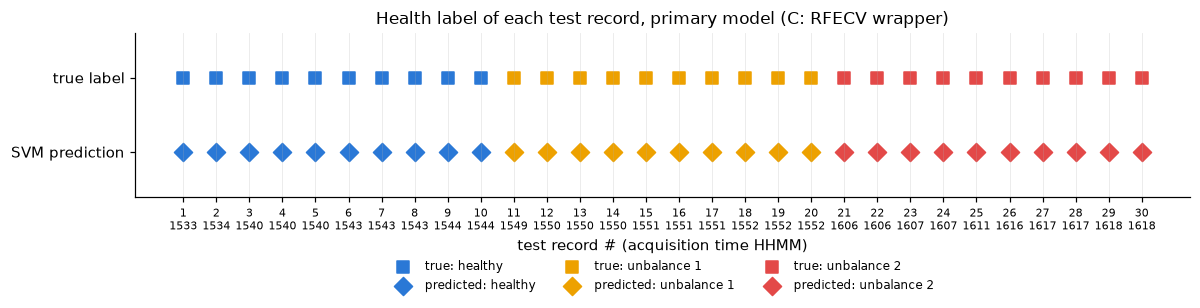

In [23]:
# Health label of every test record: true label vs predicted label, in chronological order.
fig, ax = plt.subplots(figsize=(11, 3.2))
for k, cls in enumerate(CLASSES):
    m = res.true == cls
    ax.scatter(res["#"][m], np.full(m.sum(), 1), s=70, marker="s", color=COLORS[cls], label=f"true: {cls}")
    m = res.predicted == cls
    ax.scatter(res["#"][m], np.full(m.sum(), 0), s=70, marker="D", color=COLORS[cls], label=f"predicted: {cls}")
for n, ok in zip(res["#"], res.correct):
    if not ok: ax.annotate("x", (n, 0.5), ha="center", va="center", color="black", fontsize=11, fontweight="bold")
ax.set_yticks([0, 1]); ax.set_yticklabels(["SVM prediction", "true label"]); ax.set_ylim(-0.6, 1.6)
ax.set_xticks(res["#"]); ax.set_xticklabels([f"{n}\n{t}" for n, t in zip(res["#"], res.time)], fontsize=7)
ax.set(xlabel="test record # (acquisition time HHMM)", title=f"Health label of each test record, primary model ({BEST})")
ax.grid(axis="y", visible=False); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=8)
fig.tight_layout(); plt.show()

In [24]:
# Per-record results table (true label from the appendix, prediction of every feature set, primary prediction).
KEY_FEATS = list(dict.fromkeys(FEATURE_SETS["C: RFECV wrapper"] + FEATURE_SETS["D: L1-SVM embedded"] + ["A1X"]))   # selected features + 1X for reference
show = res[["#", "file"] + KEY_FEATS + ["true"] + [f"pred_{n.split(':')[0]}" for n in searches] + ["predicted", "correct"]]
def color_cls(v):
    return f"color: {COLORS[v]}; font-weight: bold" if v in COLORS else ""
show.style.format({f: "{:.4f}" for f in KEY_FEATS}).map(color_cls, subset=["true", "predicted"] + [c for c in show.columns if c.startswith("pred_")]).hide(axis="index")

#,file,peak_bp,p2p_bp,crest_bp,A1X,true,pred_A,pred_B,pred_C,pred_D,predicted,correct
1,Data Mar-26-14 Time 1533-21.txt,0.0010,0.0020,3.3605,0.0002,healthy,healthy,healthy,healthy,healthy,healthy,True
2,Data Mar-26-14 Time 1534-22.txt,0.0018,0.0035,2.7834,0.0007,healthy,healthy,healthy,healthy,healthy,healthy,True
3,Data Mar-26-14 Time 1540-23.txt,0.0021,0.0042,2.1865,0.0012,healthy,unbalance 1,healthy,healthy,healthy,healthy,True
4,Data Mar-26-14 Time 1540-24.txt,0.0024,0.0048,2.1613,0.0014,healthy,unbalance 1,healthy,healthy,healthy,healthy,True
5,Data Mar-26-14 Time 1540-25.txt,0.0022,0.0043,2.0914,0.0013,healthy,healthy,healthy,healthy,healthy,healthy,True
6,Data Mar-26-14 Time 1543-26.txt,0.0022,0.0043,2.3908,0.0011,healthy,unbalance 2,healthy,healthy,healthy,healthy,True
7,Data Mar-26-14 Time 1543-27.txt,0.0016,0.0032,2.3126,0.0009,healthy,unbalance 2,healthy,healthy,healthy,healthy,True
8,Data Mar-26-14 Time 1543-28.txt,0.0016,0.0032,2.2732,0.0008,healthy,unbalance 2,healthy,healthy,healthy,healthy,True
9,Data Mar-26-14 Time 1544-29.txt,0.0029,0.0058,2.9095,0.0011,healthy,healthy,healthy,healthy,healthy,healthy,True
10,Data Mar-26-14 Time 1544-30.txt,0.0030,0.0060,2.2606,0.0013,healthy,unbalance 1,healthy,healthy,healthy,healthy,True


test records between the unbalance-1 and unbalance-2 training clusters on peak_bp: [26, 27, 28, 29, 30] (values 0.0197-0.0212 g; train U1 max 0.0076, U2 min 0.0247)


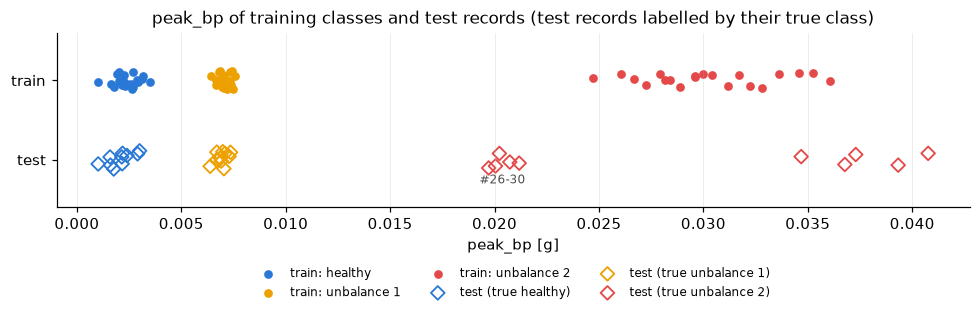

In [25]:
# Where the test records sit relative to the training classes on the primary model's feature.
feat0 = FEATURE_SETS[BEST][0]
fig, ax = plt.subplots(figsize=(9, 3.2))
rng = np.random.default_rng(1)
for k, cls in enumerate(CLASSES):
    v = train.loc[train.label == k, feat0]
    ax.scatter(v, np.full(len(v), 1) + rng.uniform(-0.12, 0.12, len(v)), s=22, color=COLORS[cls], label=f"train: {cls}")
for k, cls in enumerate(CLASSES):
    m = res.true == cls
    ax.scatter(res[feat0][m], np.zeros(m.sum()) + rng.uniform(-0.12, 0.12, m.sum()), s=40, marker="D", facecolor="none", edgecolor=COLORS[cls], lw=1.2, label=f"test (true {cls})")
lo, hi = train.loc[train.label == 1, feat0].max(), train.loc[train.label == 2, feat0].min()     # gap between the two unbalance clusters
mid = res[feat0][(res[feat0] > lo) & (res[feat0] < hi)]
if len(mid):
    ax.annotate(f"#{res['#'][mid.index].min()}-{res['#'][mid.index].max()}", (mid.mean(), -0.3), ha="center", fontsize=8, color="0.3")
    print(f"test records between the unbalance-1 and unbalance-2 training clusters on {feat0}: {sorted(res['#'][mid.index])} (values {mid.min():.4f}-{mid.max():.4f} g; train U1 max {lo:.4f}, U2 min {hi:.4f})")
ax.set_yticks([0, 1]); ax.set_yticklabels(["test", "train"]); ax.set_ylim(-0.6, 1.6)
ax.set(xlabel=f"{feat0} [g]", title=f"{feat0} of training classes and test records (test records labelled by their true class)")
ax.grid(axis="y", visible=False); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8); fig.tight_layout(); plt.show()

## 8. Discussion
**Extracted features.** Time-domain statistics of the raw signal are nearly useless on this testbed. An SVM trained on the nine raw features reaches 48 % cross-validation accuracy and 33 % on the test set, which is chance level for three classes. Mass unbalance adds a synchronous force at 21 Hz, while the overall vibration level is set by 400-800 Hz structural and bearing content that is identical in all three conditions, so the useful information lives in a narrow band around the shaft frequency. Two routes reach it. The FFT gives the 1X and 2X amplitudes directly (F up to 1120), and a 15-30 Hz band-pass filter makes the ordinary time-domain statistics measure the same 1X component (F up to 1300 for peak-to-peak, peak, RMS and standard deviation). Speed tracking of the 1X peak is essential, since reading the spectrum at the nominal 20 Hz would destroy the feature.

**Feature selection feeding the model.** The three selection families agreed on the ranking (rank correlation 0.78-0.97) and each produced a concrete input set for the SVM. The ANOVA filter kept the eight features with F above 100, all of them amplitude measures of the 1X component in one form or another. RFECV kept a single feature, the band-pass peak. The L1-penalized SVM kept two, the band-pass peak-to-peak (an amplitude feature) and the band-pass crest factor (a shape feature), discarding the other amplitude features as redundant. All three selected sets reach 100 % cross-validation accuracy and classify the 30 test records correctly, so the selection methods identified sufficient inputs and the classifier confirms it.

**Modelling technique and the tie-break.** The classes are linearly separable in every selected set, so the linear kernel is chosen and RBF and polynomial kernels add nothing. Separability has a side effect: many grid points tie at 100 % cross-validation accuracy, and the choice of C among them is not decided by the data. The sensitivity check on the one-feature set C makes the consequence visible. With C = 0.01 the SVM places its level-1 / level-2 threshold at 0.0213 g, right on top of test records 26-30 (0.0197-0.0212 g), and labels them level 1, which drops the test accuracy to 83 %. With C of 0.1 or more the threshold moves to 0.016-0.018 g, close to the midpoint of the training gap (0.0076 to 0.0247 g), and all 30 records are correct. The tie-break rule used here, simplest kernel then largest C, selects the hard-margin solution and therefore the midpoint threshold. The two-feature set D is not sensitive to this choice, because the crest factor separates the sinusoidal unbalance records from the noise-like healthy records independently of the amplitude. The from-scratch Pegasos SVM reproduced the scikit-learn hyperplane on the binary problem (direction cosine 0.9999), which confirms the implementation.

**Results.** The primary model (set C, band-pass peak, linear kernel) and the sets B and D label every test record correctly, a 10/10/10 confusion matrix with precision and recall of 1.000 for every class. Records 26-30 are correctly labelled level 2, but on the primary feature they lie between the level-1 training cluster (at most 0.0076 g) and the level-2 cluster (at least 0.0247 g), at 0.0197-0.0212 g. They are the records with the smallest margin and the ones whose label depends on where the threshold falls, which suggests a smaller effective unbalance than the training level 2, for example a different screw position. A three-level classifier only resolves the levels it was trained on. A continuous severity indicator such as the band-pass peak or the 1X amplitude is more informative when the unbalance can take intermediate values.

**Limitations.** The test set is small (10 records per class) and was recorded on the same day as the training data, so the perfect score is not a guarantee for other speeds, loads or sensors. Perfect separability means that cross-validation cannot discriminate between kernels, penalties or selected sets; those choices rest on parsimony, the tie-break rule and physical interpretability. A minimal one-feature model is attractive but, as the sensitivity check shows, it has no redundancy at intermediate severities, so set D (one amplitude and one shape feature) is the more robust choice for deployment.

## 9. Conclusion
* Time-domain statistics of the raw signal (RMS, peak-to-peak, standard deviation and six others) cannot separate healthy, level-1 and level-2 unbalance. An SVM trained on them performs at chance level (33 %) on the test set. The same statistics on a 15-30 Hz band-pass filtered signal, and the 1X and 2X FFT amplitudes, separate the three classes perfectly (ANOVA F above 1000 for the best features).
* Filter (ANOVA), wrapper (RFECV) and embedded (L1-SVM) selection methods agree on the ranking and each delivered an input set for the SVM, with eight, one and two features respectively. All three reach 100 % cross-validation accuracy and classify all 30 test records correctly, so feature selection and prediction are consistent.
* A linear-kernel SVM is selected for every informative set because the classes are linearly separable. Ties in cross-validation accuracy are broken toward the hard-margin solution (largest C), which places thresholds midway between neighbouring training clusters. With a small C the one-feature model would mislabel the five intermediate test records, so the tie-break matters.
* On the 30 test records the primary model predicts every record correctly: **records 1-10 healthy, 11-20 unbalance level 1, 21-30 unbalance level 2**, a diagonal 10/10/10 confusion matrix with precision and recall of 1.0 for every class. Records 26-30 lie between the two unbalance training clusters and are the least certain, which a continuous severity indicator reveals and a class label hides. For deployment the two-feature set D (band-pass peak-to-peak and crest factor) is recommended as the more robust choice.
* Results are saved in `results/test_health_assessment.csv` together with the extracted features of the training and test sets.